# Mamba projekt - EDA és képadat-ellenőrzés

Ez a notebook a `src/mamba.py` vizsgálatait rendezi át áttekinthető, újrafuttatható formában. A cellák kommentálva vannak, és az ábrákat a `plots/` mappába is elmentik.

A notebook fő részei:

1. projektútvonal és adatok betöltése;
2. alapvető adatminőségi ellenőrzések;
3. fajok képszámának elemzése;
4. mérgezőségi címkék elemzése;
5. képminta beolvasása ZIP-archívumból;
6. a korábban elkészített plotok megjelenítése;
7. a `mamba.py`-ban szereplő egyedi CNN architektúrájának bemutatása.

A képes cellák csak akkor futnak végig, ha a megfelelő ZIP-fájl tényleg megtalálható.

In [1]:
from pathlib import Path
import zipfile

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import pandas as pd

# A notebookot Jupyterből többféle aktuális mappából is el lehet indítani.
# Ezért a projektgyökeret a src/ és data/ mappák alapján keressük meg.
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "src").is_dir() and (candidate / "data").is_dir()
    ),
    Path.cwd(),
)
DATA_DIR = PROJECT_ROOT / "data"
PLOTS_DIR = PROJECT_ROOT / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
METADATA_PATH = DATA_DIR / "merged_snake_metadata.csv"
ZIP_PATH = DATA_DIR / "train_images_small.zip"
if not METADATA_PATH.is_file():
    raise FileNotFoundError(f"Nem található a metadata CSV: {METADATA_PATH}")
df = pd.read_csv(METADATA_PATH)
print(f"Projektgyökér: {PROJECT_ROOT}")
print(f"Metadata fájl: {METADATA_PATH}")
print(f"Sorok száma: {df.shape[0]:,}")
print(f"Oszlopok száma: {df.shape[1]}")

Projektgyökér: c:\Users\BAU Trade Kft\OneDrive\Asztali gép\Mamba-Project
Metadata fájl: c:\Users\BAU Trade Kft\OneDrive\Asztali gép\Mamba-Project\data\merged_snake_metadata.csv
Sorok száma: 66,454
Oszlopok száma: 7


## 1. Alapvető adatminőségi ellenőrzés

Megnézzük az oszlopokat, az adattípusokat, a hiányzó értékeket és a teljes soros duplikátumokat. Ezek az ellenőrzések segítenek kiszűrni azokat a problémákat, amelyek a későbbi tanítás előtt adatvesztést vagy hibás címkézést okozhatnak.

In [2]:
# A pandas info() részletesen megmutatja az oszlopok típusát és a nem üres értékek számát.
df.info()
display(df.head())
display(df.describe(include="all").transpose().head(20))
duplicates = int(df.duplicated().sum())
missing = df.isna().sum()
missing_df = pd.DataFrame(
        {
            "Hiányzó darabszám": missing,
            "Hiányzó arány (%)": (missing / len(df) * 100).round(2),
        }
    )
print(f"Teljes soros duplikátumok: {duplicates:,}")
print(f"Egyedi képutak száma: {df['image_path'].nunique():,}")
print("Hiányzó értékek oszloponként:")
display(missing_df[missing_df["Hiányzó darabszám"] > 0])

<class 'pandas.DataFrame'>
RangeIndex: 66454 entries, 0 to 66453
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   observation_id  66454 non-null  int64
 1   endemic         66454 non-null  bool 
 2   binomial_name   66454 non-null  str  
 3   code            66454 non-null  str  
 4   image_path      66454 non-null  str  
 5   class_id        66454 non-null  int64
 6   MIVS            66454 non-null  int64
dtypes: bool(1), int64(3), str(3)
memory usage: 3.1 MB


,observation_id,endemic,binomial_name,code,image_path,class_id,MIVS
0,117940,False,Bitis caudalis,ZA,168482.JPG,157,0
1,37280129,False,Amphiesma stolatum,TH,59067968.jpg,66,0
2,27445689,False,Lachesis muta,BR,42704088.jpg,857,1
3,68796818,True,Vipera berus,NL,111487306.jpeg,1736,1
4,68796816,False,Coronella austriaca,NL,111486989.jpeg,387,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
observation_id,66454.0,NaN,NaN,NaN,73839270.372077,44260827.283912,1233.0,35447205.5,71663021.5,112215971.25,147868774.0
endemic,66454,2,False,60523,NaN,NaN,NaN,NaN,NaN,NaN,NaN
binomial_name,66454,296,Natrix natrix,1839,NaN,NaN,NaN,NaN,NaN,NaN,NaN
code,66454,188,MX,5002,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_path,66454,66454,168482.JPG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class_id,66454.0,NaN,NaN,NaN,946.080236,485.071587,43.0,512.0,951.0,1316.0,1783.0
MIVS,66454.0,NaN,NaN,NaN,0.199988,0.399994,0.0,0.0,0.0,0.0,1.0


Teljes soros duplikátumok: 0
Egyedi képutak száma: 66,454
Hiányzó értékek oszloponként:


,Hiányzó darabszám,Hiányzó arány (%)


## 2. Fajok és osztályok eloszlása

A `class_id` a modell numerikus osztályazonosítója, a `binomial_name` pedig a tudományos fajnév. Először kiszámoljuk az egyedi osztályok számát, majd megvizsgáljuk a leggyakoribb és legritkább fajokat.

In [3]:
class_count = df["class_id"].nunique()
species_count = df["binomial_name"].nunique()
species_distribution = df["binomial_name"].value_counts()
print(f"Különböző class_id értékek száma: {class_count}")
print(f"Különböző fajnevek száma: {species_count}")
print("\nTop 5 leggyakoribb faj:")
display(species_distribution.head(5).to_frame("Képek száma"))
print("5 legritkább faj:")
display(species_distribution.tail(5).to_frame("Képek száma"))

Különböző class_id értékek száma: 296
Különböző fajnevek száma: 296

Top 5 leggyakoribb faj:


,Képek száma
binomial_name,
Natrix natrix,1839
Natrix tessellata,1583
Coronella austriaca,1489
Vipera berus,1221
Indotyphlops braminus,1065


5 legritkább faj:


,Képek száma
binomial_name,
Micrurus altirostris,101
Oligodon octolineatus,101
Macrovipera lebetinus,100
Porthidium ophryomegas,100
Pseudonaja mengdeni,96


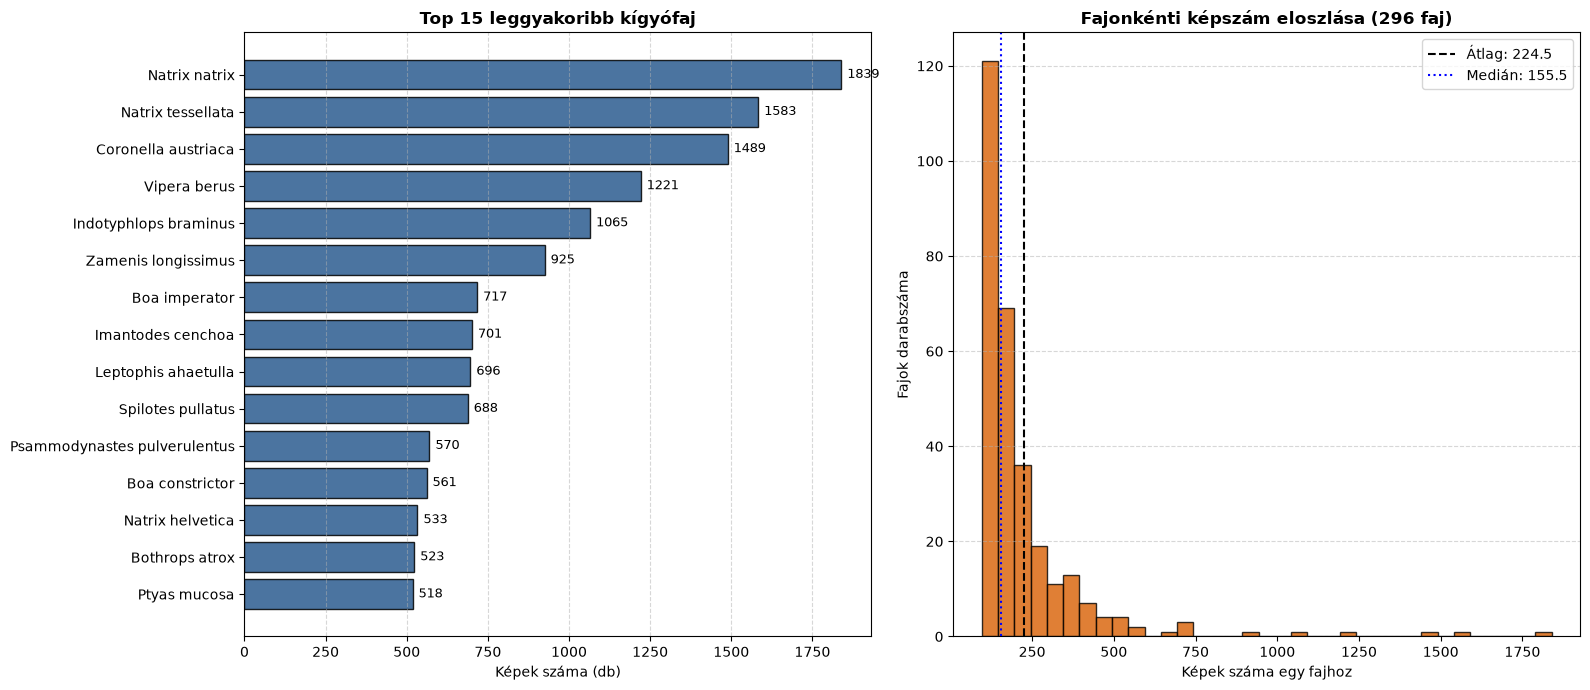

In [4]:
# Bal oldalon a 15 leggyakoribb faj látható.
# Jobb oldalon azt vizsgáljuk, hogy egy fajhoz hány kép tartozik.
top15 = species_distribution.head(15).sort_values(ascending=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
bars = ax1.barh(top15.index, top15.values, color="#2b5c8f", edgecolor="black", alpha=0.85)
for bar in bars:
    width = bar.get_width()
    ax1.text(width + max(top15.values) * 0.01, bar.get_y() + bar.get_height() / 2,
                 f"{int(width)}", va="center", fontsize=9)
ax1.set_title("Top 15 leggyakoribb kígyófaj", fontweight="bold")
ax1.set_xlabel("Képek száma (db)")
ax1.grid(axis="x", linestyle="--", alpha=0.5)
ax2.hist(species_distribution.values, bins=35, color="#d95f02", edgecolor="black", alpha=0.8)
ax2.axvline(species_distribution.mean(), color="black", linestyle="--",
                label=f"Átlag: {species_distribution.mean():.1f}")
ax2.axvline(species_distribution.median(), color="blue", linestyle=":",
                label=f"Medián: {species_distribution.median():.1f}")
ax2.set_title(f"Fajonkénti képszám eloszlása ({species_count} faj)", fontweight="bold")
ax2.set_xlabel("Képek száma egy fajhoz")
ax2.set_ylabel("Fajok darabszáma")
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_species_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Mérgezőségi címkék vizsgálata

A projektben a mérgezőséget az `MIVS` oszlop jelöli. Az eloszlás megmutatja, hogy mennyire kiegyensúlyozott a bináris feladat, és fontos támpontot ad a loss súlyozásához.

,Címke,Képek száma
0,Nem mérgező,53164
1,Mérgező,13290


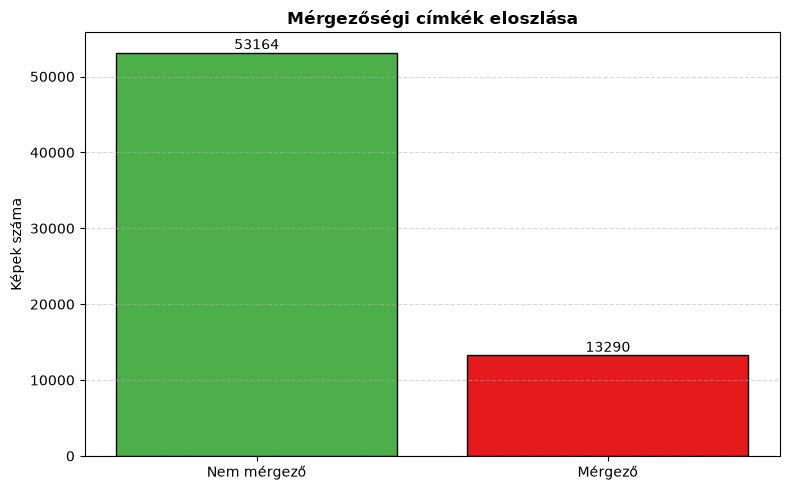

In [5]:
if "MIVS" not in df.columns:
    raise ValueError("A metadata nem tartalmazza az MIVS oszlopot.")
venomous_counts = df["MIVS"].value_counts().sort_index()
venomous_labels = {0: "Nem mérgező", 1: "Mérgező"}
venomous_names = [venomous_labels.get(int(value), str(value)) for value in venomous_counts.index]
display(pd.DataFrame({"Címke": venomous_names, "Képek száma": venomous_counts.values}))
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(venomous_names, venomous_counts.values,
                  color=["#4daf4a", "#e41a1c"][:len(venomous_counts)], edgecolor="black")
for bar, count in zip(bars, venomous_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(int(count)),
                ha="center", va="bottom")
ax.set_title("Mérgezőségi címkék eloszlása", fontweight="bold")
ax.set_ylabel("Képek száma")
ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_venomous_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Összefoglalás

Az EDA végén érdemes külön figyelni a fajok közötti erős képszám-eltérésekre, az `MIVS` címkék egyensúlyára, a hiányzó vagy duplikált rekordokra, valamint arra, hogy a ZIP-ből beolvasott képek ténylegesen dekódolhatók-e. Az elkészített ábrák a `plots/` mappában maradnak, így később a riportban vagy a prezentációban is felhasználhatók.